# Forelesning 21: To-dimensjonale randverdiproblemer og varmeligningen i 2D

Dette notatboket hører til delkapitlene

* **Iterative metoder: Jacobi- og Gauss-Seidel-iterasjon** (fra F20, gjenbrukt i 2D)
* **To-dimensjonale randverdiproblemer: Laplace- og Poisson-likningen**
* **Et PDE-eksempel: numerisk løsning av varmeligningen -- To romdimensjoner**

i kompendiet. Vi implementerer og tester:

1. Jacobi/Gauss-Seidel-iterasjon for 2D Poisson-/Laplace-likningen $\Delta u = f$ på et rektangel,
   med Dirichlet-betingelser (inkludert posisjonsavhengige/stykkevise randverdier).
2. Eksplisitt Euler i tid for 2D varmeligningen, og stabilitetsgrensen $r=\dfrac{\Delta t}{h^2}\le \dfrac14$.


In [1]:

import numpy as np
import matplotlib.pyplot as plt


## 1. Jacobi- og Gauss-Seidel-iterasjon for 2D Poisson-likningen

Vi diskretiserer $\Delta u = f$ på rektanglet $[0,L_x]\times[0,L_y]$ med et rutenett
$x_i = i h,\ y_j = j h$ ($h=\Delta x=\Delta y$), og bruker 5-punkts-stencilen fra kompendiet
(seksjon om 2D randverdiproblemer):

$$U_{i,j} = \frac{1}{4}\Big(U_{i+1,j}+U_{i-1,j}+U_{i,j+1}+U_{i,j-1} - h^2 f_{i,j}\Big).$$

Randpunktene settes til de gitte Dirichlet-verdiene (som her kan være en funksjon av posisjonen
langs randen -- altså stykkevis/posisjonsavhengig, ikke nødvendigvis konstant).


### Hvordan rutenettet ligger lagret i matrisen `U`

**$L_x$ og $L_y$** er lengden og bredden til rektanglet vi løser på, $[0,L_x]\times[0,L_y]$. De sendes inn som argumenter til funksjonene under (f.eks. `Lx = Ly = 1.0` gir enhetskvadratet). I kompendiet heter området $[a,b]\times[c,d]$; her antar vi bare $a=c=0$ og kaller $b=L_x$, $d=L_y$.

Med $N_x$ intervaller i $x$-retning og $N_y$ i $y$-retning er $h = L_x/N_x = L_y/N_y$, og gitterpunktene er
$$x_i = i h,\quad i=0,\ldots,N_x, \qquad y_j = j h,\quad j=0,\ldots,N_y .$$

**Viktig:** I NumPy er første indeks *raden* og andre indeks *kolonnen*. Vi lar raden svare til $y$ og kolonnen til $x$, så

$$\texttt{U[j, i]} \approx u(x_i, y_j) = U_{i,j}.$$

Legg merke til at rekkefølgen på indeksene er *byttet om* i forhold til den matematiske notasjonen $U_{i,j}$. Det betyr at

| I koden | Matematisk | Del av randen |
|---|---|---|
| `U[0, :]`  | $j=0$, dvs. $y = 0$         | nederste kant |
| `U[-1, :]` | $j=N_y$, dvs. $y = N_y h = L_y$ | øverste kant |
| `U[:, 0]`  | $i=0$, dvs. $x = 0$         | venstre kant |
| `U[:, -1]` | $i=N_x$, dvs. $x = N_x h = L_x$ | høyre kant |

(`-1` betyr «siste element» i Python.)

Når vi senere plotter med `plt.imshow(U, origin="lower", ...)`, tegnes rad 0 *nederst* -- slik at bildet får $y$-aksen oppover, som vi er vant til. Uten `origin="lower"` setter matplotlib rad 0 øverst, og bildet blir speilvendt.


In [2]:

def sett_rand(U, g, x, y):
    '''Setter Dirichlet-randverdier på et (Ny+1)x(Nx+1)-rutenett U, gitt en funksjon
    g(x, y) som er definert (og brukes) langs hele randen av rektanglet [0,Lx]x[0,Ly].
    NB: U[j, i] svarer til punktet (x_i, y_j) -- rad = y-retning, kolonne = x-retning.'''
    Ny1, Nx1 = U.shape
    U[0, :]     = [g(xi, y[0])  for xi in x]   # rad j = 0:     nederste kant (y = 0)
    U[-1, :]    = [g(xi, y[-1]) for xi in x]   # rad j = Ny:    øverste kant  (y = Ly)
    U[:, 0]     = [g(x[0],  yj) for yj in y]   # kolonne i = 0:  venstre kant (x = 0)
    U[:, -1]    = [g(x[-1], yj) for yj in y]   # kolonne i = Nx: høyre kant   (x = Lx)
    return U


def jacobi_poisson2d(f, g, Lx, Ly, Nx, Ny, tol=1e-8, maxit=200_000):
    '''Løser Delta u = f på [0,Lx] x [0,Ly] med Dirichlet-rand g(x,y),
    ved Jacobi-iterasjon. Krever Nx == Ny og dermed h = Lx/Nx = Ly/Ny.
    Returnerer (x, y, U, antall_iterasjoner).'''
    h = Lx / Nx
    assert abs(h - Ly / Ny) < 1e-12, "Krever kvadratiske celler (samme h i x og y)"
    x = h * np.arange(Nx + 1)
    y = h * np.arange(Ny + 1)
    U = np.zeros((Ny + 1, Nx + 1))
    U = sett_rand(U, g, x, y)
    F = np.array([[f(xi, yj) for xi in x] for yj in y])
    for it in range(maxit):
        Unytt = U.copy()
        Unytt[1:-1, 1:-1] = 0.25 * (U[1:-1, 2:] + U[1:-1, :-2] +
                                     U[2:, 1:-1] + U[:-2, 1:-1] -
                                     h**2 * F[1:-1, 1:-1])
        endring = np.max(np.abs(Unytt - U))
        U = Unytt
        if endring < tol:
            break
    return x, y, U, it + 1


def gauss_seidel_poisson2d(f, g, Lx, Ly, Nx, Ny, tol=1e-8, maxit=200_000):
    '''Som jacobi_poisson2d, men med Gauss-Seidel-iterasjon
    (bruker oppdaterte verdier fra samme sveip).'''
    h = Lx / Nx
    assert abs(h - Ly / Ny) < 1e-12, "Krever kvadratiske celler (samme h i x og y)"
    x = h * np.arange(Nx + 1)
    y = h * np.arange(Ny + 1)
    U = np.zeros((Ny + 1, Nx + 1))
    U = sett_rand(U, g, x, y)
    F = np.array([[f(xi, yj) for xi in x] for yj in y])
    for it in range(maxit):
        endring = 0.0
        for j in range(1, Ny):
            for i in range(1, Nx):
                gammel = U[j, i]
                U[j, i] = 0.25 * (U[j, i + 1] + U[j, i - 1] +
                                   U[j + 1, i] + U[j - 1, i] -
                                   h**2 * F[j, i])
                endring = max(endring, abs(U[j, i] - gammel))
        if endring < tol:
            break
    return x, y, U, it + 1


### Test mot en kjent løsning (manufactured solution)

Vi tester koden mot et problem der vi *vet* den eksakte løsningen: la
$u(x,y) = \sin(\pi x)\sin(\pi y)$ på $[0,1]\times[0,1]$ med $u=0$ på hele randen.
Da er $f = \Delta u = -2\pi^2 \sin(\pi x)\sin(\pi y)$.


Jacobi brukte 2007 iterasjoner.
Maks feil mot eksakt løsning: 0.0013116690419393562


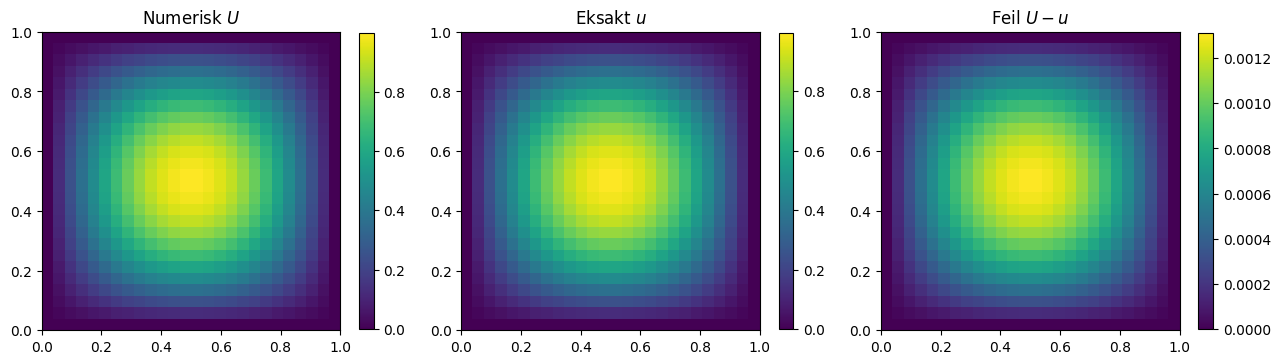

In [3]:

f_test = lambda x, y: -2 * np.pi**2 * np.sin(np.pi * x) * np.sin(np.pi * y)
g_test = lambda x, y: 0.0
u_eksakt = lambda x, y: np.sin(np.pi * x) * np.sin(np.pi * y)

N = 25
x, y, U, nit = jacobi_poisson2d(f_test, g_test, 1.0, 1.0, N, N, tol=1e-9)
X, Y = np.meshgrid(x, y)
Ueks = u_eksakt(X, Y)
print(f"Jacobi brukte {nit} iterasjoner.")
print("Maks feil mot eksakt løsning:", np.max(np.abs(U - Ueks)))

fig, axs = plt.subplots(1, 3, figsize=(13, 4))
for ax, data, title in zip(axs, [U, Ueks, U - Ueks],
                            ["Numerisk $U$", "Eksakt $u$", "Feil $U-u$"]):
    im = ax.imshow(data, origin="lower", extent=[0, 1, 0, 1], cmap="viridis")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()


### Posisjonsavhengig (stykkevis) Dirichlet-rand

I øving 6 møter man 2D-problemer der randverdiene ikke er konstante langs hver kant, men gitt
som stykkevis lineære funksjoner av posisjonen. Teknikken er akkurat den samme -- det er bare
funksjonen $g(x,y)$ i `sett_rand` som blir mer innviklet. Her illustrerer vi metoden med et
eget eksempel (med andre tall enn i øvingen): temperaturen på randen av en kvadratisk plate
varierer stykkevis lineært langs hver av de fire kantene.


Gauss-Seidel brukte 1631 iterasjoner.


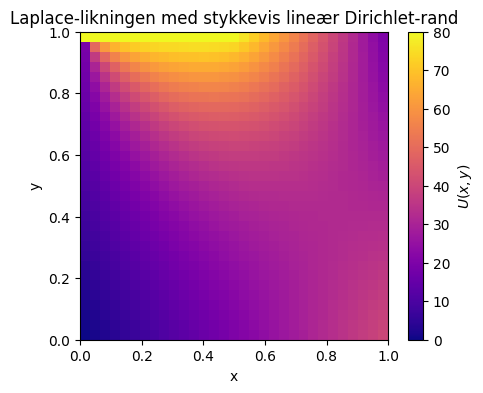

In [4]:

def g_stykkevis(x, y, L=1.0):
    '''Illustrasjonseksempel: stykkevis lineær randverdi på kanten av [0,L] x [0,L].
    Returnerer en fornuftig verdi også i de fire hjørnene (kontinuerlig langs randen).'''
    eps = 1e-9
    if abs(y) < eps:          # underste kant: lineær økning fra 0 til 40
        return 40.0 * (x / L)
    if abs(y - L) < eps:      # øverste kant: konstant 80 for x<L/2, så lineært ned til 20
        return 80.0 if x < L / 2 else 80.0 - 120.0 * (x - L / 2) / L
    if abs(x) < eps:          # venstre kant: lineær fra 0 (nede) til 20 (oppe)
        return 20.0 * (y / L)
    if abs(x - L) < eps:      # høyre kant: lineær fra 40 (nede) til 20 (oppe)
        return 40.0 - 20.0 * (y / L)
    raise ValueError("(x, y) ligger ikke på randen")


f_null = lambda x, y: 0.0   # Laplace-likningen: ingen kilde

N = 30
x, y, U, nit = gauss_seidel_poisson2d(f_null, g_stykkevis, 1.0, 1.0, N, N, tol=1e-8)
print(f"Gauss-Seidel brukte {nit} iterasjoner.")

plt.figure(figsize=(5, 4))
im = plt.imshow(U, origin="lower", extent=[0, 1, 0, 1], cmap="plasma")
plt.colorbar(im, label="$U(x,y)$")
plt.title("Laplace-likningen med stykkevis lineær Dirichlet-rand")
plt.xlabel("x"); plt.ylabel("y")
plt.show()


## 2. Varmeligningen i 2D: eksplisitt Euler

Fra kompendiet (seksjonen om varmeligningen, "To romdimensjoner"):

$$U_{i,j}^{n+1} = U_{i,j}^{n} + r\Big(U_{i+1,j}^n + U_{i-1,j}^n + U_{i,j+1}^n + U_{i,j-1}^n - 4U_{i,j}^n\Big),
\qquad r = \frac{\Delta t}{h^2},$$

som er stabil for $r \le \dfrac14$ (når $\Delta x=\Delta y=h$).


In [5]:

def heat2d_eksplisitt(u0, Lx, Ly, Nx, Ny, dt, nsteps, randverdi=0.0):
    '''Løser 2D varmeligningen u_t = u_xx + u_yy på [0,Lx] x [0,Ly] med konstant
    Dirichlet-rand "randverdi" og initialbetingelse u0(x, y), ved eksplisitt Euler.
    Returnerer x, y, og en liste med rutenett U ved hvert lagrede tidspunkt.'''
    h = Lx / Nx
    assert abs(h - Ly / Ny) < 1e-12, "Krever kvadratiske celler (samme h i x og y)"
    r = dt / h**2
    x = h * np.arange(Nx + 1)
    y = h * np.arange(Ny + 1)
    X, Y = np.meshgrid(x, y)
    U = u0(X, Y).astype(float)
    U[0, :] = U[-1, :] = U[:, 0] = U[:, -1] = randverdi
    historikk = [U.copy()]
    for n in range(nsteps):
        Unytt = U.copy()
        Unytt[1:-1, 1:-1] = U[1:-1, 1:-1] + r * (
            U[1:-1, 2:] + U[1:-1, :-2] + U[2:, 1:-1] + U[:-2, 1:-1] - 4 * U[1:-1, 1:-1]
        )
        U = Unytt
        historikk.append(U.copy())
    return x, y, historikk, r


r = 0.2400 (<= 0.25 kreves for stabilitet)


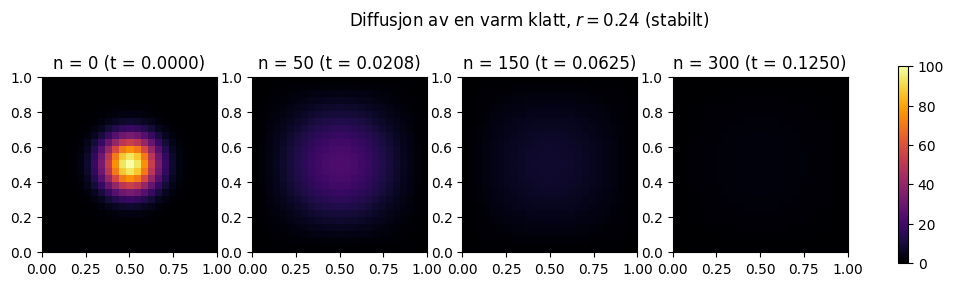

In [6]:

# Initialbetingelse: en "varm klatt" i midten av en kald plate
bump = lambda x, y: 100.0 * np.exp(-40 * ((x - 0.5)**2 + (y - 0.5)**2))

N = 24
h = 1.0 / N
r_stabil = 0.24          # < 1/4 -> stabilt
dt = r_stabil * h**2
x, y, hist, r = heat2d_eksplisitt(bump, 1.0, 1.0, N, N, dt, nsteps=300)
print(f"r = {r:.4f} (<= 0.25 kreves for stabilitet)")

tider_vis = [0, 50, 150, 300]
fig, axs = plt.subplots(1, len(tider_vis), figsize=(13, 3.2))
for ax, n in zip(axs, tider_vis):
    im = ax.imshow(hist[n], origin="lower", extent=[0, 1, 0, 1],
                    cmap="inferno", vmin=0, vmax=100)
    ax.set_title(f"n = {n} (t = {n*dt:.4f})")
fig.colorbar(im, ax=axs, shrink=0.8)
plt.suptitle("Diffusjon av en varm klatt, $r = 0.24$ (stabilt)")
plt.show()


### Instabilitet når $r > 1/4$

Vi gjentar med $r = 0.3$ for å demonstrere at skjemaet da blåser opp, akkurat som beskrevet
i kompendiets stabilitetsboks.


r = 0.3000
Maks |U| ved n=0, 30, 60, 90, 120, 150: [100.0, 28.285766426718048, 16.4722410908041, 19.049743470114493, 200881.0429145318, 4340623729.790079]


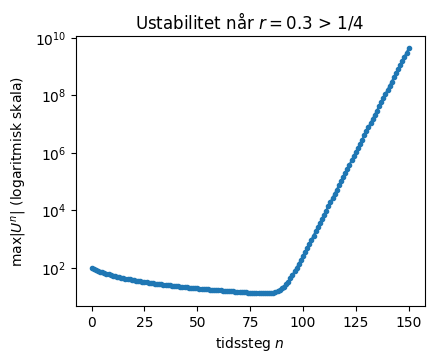

In [7]:

r_ustabil = 0.3           # > 1/4 -> ustabilt
dt_u = r_ustabil * h**2
x, y, hist_u, r_u = heat2d_eksplisitt(bump, 1.0, 1.0, N, N, dt_u, nsteps=150)
print(f"r = {r_u:.4f}")
print("Maks |U| ved n=0, 30, 60, 90, 120, 150:",
      [float(np.max(np.abs(hist_u[n]))) for n in (0, 30, 60, 90, 120, 150)])

plt.figure(figsize=(4.5, 3.5))
plt.semilogy([np.max(np.abs(Un)) for Un in hist_u], marker=".")
plt.xlabel("tidssteg $n$"); plt.ylabel(r"$\max |U^n|$ (logaritmisk skala)")
plt.title(f"Ustabilitet når $r = {r_ustabil}$ > 1/4")
plt.show()


## Oppsummering

* 2D Poisson-/Laplace-likningen løses med samme Jacobi-/Gauss-Seidel-iterasjon som i 1D,
  bare med 5-punkts-stencilen i rommet. Dirichlet-randen kan være en vilkårlig (også
  stykkevis) funksjon av posisjonen langs randen.
* 2D varmeligningen med eksplisitt Euler er stabil for $r=\Delta t/h^2 \le 1/4$
  (med $\Delta x = \Delta y = h$); overskrides grensen, blåser løsningen opp.
